In [1]:
!pip install shap -q

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import shap
import pickle
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    roc_auc_score, roc_curve,
    precision_recall_curve, average_precision_score,
    classification_report, confusion_matrix,
)
from xgboost import XGBClassifier

plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor': '#F9F9F9',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'font.family': 'sans-serif',
    'axes.titlesize': 13,
    'axes.labelsize': 11,
})

BLUE   = '#1B4F8A'
RED    = '#C0392B'
GREEN  = '#27AE60'
ORANGE = '#E67E22'
GREY   = '#95A5A6'

FIGURES   = Path('/content/figures')
PROCESSED = Path('/content/processed')
MODELS    = Path('/content/models')
FIGURES.mkdir(exist_ok=True)
MODELS.mkdir(exist_ok=True)

print("Environment ready.")


Environment ready.


Load Data

In [3]:
df = pd.read_csv('telco_clean.csv')

print(f"Subscribers : {len(df):,}")
print(f"Churn rate  : {df['Churn_Binary'].mean()*100:.1f}%")
print(f"Columns     : {list(df.columns)}")


Subscribers : 7,043
Churn rate  : 26.5%
Columns     : ['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn', 'Churn_Binary', 'TenureBand', 'ChargeBand']


Feature engineering

In [4]:
# Drop columns that leak the target, are identifiers, or are derived buckets
# TenureBand and ChargeBand are derived from tenure and MonthlyCharges — using both
# would be redundant and could cause issues with some models
drop_cols = ['customerID', 'Churn', 'Churn_Binary']
for c in ['TenureBand', 'ChargeBand']:
    if c in df.columns:
        drop_cols.append(c)

features = df.drop(columns=drop_cols).copy()
target   = df['Churn_Binary'].copy()

# ── Binary encode Yes/No service columns ─────────────────────────────────────
# 'No internet service' and 'No phone service' are treated the same as 'No'
# — the subscriber does not have that service, so it cannot protect them from churn
service_cols = [
    'MultipleLines', 'OnlineSecurity', 'OnlineBackup',
    'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies'
]
for col in service_cols:
    features[col] = features[col].apply(
        lambda x: 1 if x == 'Yes' else 0
    )

simple_binary = ['Partner', 'Dependents', 'PhoneService', 'PaperlessBilling']
for col in simple_binary:
    features[col] = (features[col] == 'Yes').astype(int)

features['gender'] = (features['gender'] == 'Male').astype(int)

# ── Contract — ordinal encode ─────────────────────────────────────────────────
# Month-to-month = 0 (highest churn risk), Two year = 2 (lowest)
# Ordinal encoding preserves the natural ordering
features['Contract'] = features['Contract'].map({
    'Month-to-month': 0, 'One year': 1, 'Two year': 2
})

# ── Internet service — two derived binary flags ───────────────────────────────
# Fibre optic is associated with higher churn (we saw this in Notebook 01)
# Having any internet at all increases engagement with the service
features['is_fiber_optic'] = (features['InternetService'] == 'Fiber optic').astype(int)
features['has_internet']   = (features['InternetService'] != 'No').astype(int)
features = features.drop(columns=['InternetService'])

# ── Payment method ────────────────────────────────────────────────────────────
# Electronic check has a notably higher churn rate — easier to cancel
# Automatic payment methods (bank transfer, credit card) create friction around cancellation
features['is_electronic_check'] = (features['PaymentMethod'] == 'Electronic check').astype(int)
features = features.drop(columns=['PaymentMethod'])

# ── Derived features ──────────────────────────────────────────────────────────
# avg_monthly_spend: more stable than MonthlyCharges alone for new subscribers
features['avg_monthly_spend'] = features['TotalCharges'] / (features['tenure'] + 1)

# service_count: more services = more embedded in the product = lower churn risk
features['service_count'] = features[[
    'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
    'TechSupport', 'StreamingTV', 'StreamingMovies'
]].sum(axis=1)

print(f"Features after engineering: {features.shape[1]}")
print(f"\nFeature list:")
for col in features.columns:
    print(f"  {col}")
print(f"\nNull values: {features.isnull().sum().sum()}")
print(f"Target distribution — Churn: {target.mean()*100:.1f}%  No churn: {(1-target.mean())*100:.1f}%")


Features after engineering: 22

Feature list:
  gender
  SeniorCitizen
  Partner
  Dependents
  tenure
  PhoneService
  MultipleLines
  OnlineSecurity
  OnlineBackup
  DeviceProtection
  TechSupport
  StreamingTV
  StreamingMovies
  Contract
  PaperlessBilling
  MonthlyCharges
  TotalCharges
  is_fiber_optic
  has_internet
  is_electronic_check
  avg_monthly_spend
  service_count

Null values: 0
Target distribution — Churn: 26.5%  No churn: 73.5%


Train/test split

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    features, target,
    test_size=0.20,
    random_state=42,
    stratify=target   # ensures both splits have the same churn rate
)

print(f"Training set   : {len(X_train):,} subscribers  ({y_train.mean()*100:.1f}% churn)")
print(f"Test set       : {len(X_test):,} subscribers   ({y_test.mean()*100:.1f}% churn)")
print(f"\nstratify=target ensures both splits have the same class ratio.")
print("Without this, random chance could put more churners in one split than the other,")
print("leading to misleading evaluation metrics.")


Training set   : 5,634 subscribers  (26.5% churn)
Test set       : 1,409 subscribers   (26.5% churn)

stratify=target ensures both splits have the same class ratio.
Without this, random chance could put more churners in one split than the other,
leading to misleading evaluation metrics.


Baseline: Logistic Regression

In [6]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

lr_model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',   # equivalent to scale_pos_weight in XGBoost
    random_state=42
)
lr_model.fit(X_train_scaled, y_train)

lr_probs = lr_model.predict_proba(X_test_scaled)[:, 1]
lr_auc   = roc_auc_score(y_test, lr_probs)

# Cross-validated AUC on training set (more reliable than single-split)
cv       = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
lr_cv    = cross_val_score(lr_model, X_train_scaled, y_train, cv=cv, scoring='roc_auc')

print(f"Logistic Regression — Baseline")
print(f"  Test AUC            : {lr_auc:.4f}")
print(f"  5-fold CV AUC       : {lr_cv.mean():.4f} (+/- {lr_cv.std()*2:.4f})")
print()
print("This is the bar XGBoost must clear to justify its added complexity.")


Logistic Regression — Baseline
  Test AUC            : 0.8461
  5-fold CV AUC       : 0.8486 (+/- 0.0235)

This is the bar XGBoost must clear to justify its added complexity.


Main model: XGBoost

In [7]:
# scale_pos_weight tells XGBoost how much more to penalise missing a churner
# compared to incorrectly flagging a non-churner
# Formula: count of non-churners / count of churners
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print(f"scale_pos_weight = {scale_pos_weight:.2f}")
print("(XGBoost will treat each churner as equivalent to {:.1f} non-churners in the loss function)".format(scale_pos_weight))

xgb_model = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    eval_metric='logloss',
    verbosity=0,
)
xgb_model.fit(X_train, y_train)

xgb_probs = xgb_model.predict_proba(X_test)[:, 1]
xgb_auc   = roc_auc_score(y_test, xgb_probs)

xgb_cv = cross_val_score(xgb_model, X_train, y_train, cv=cv, scoring='roc_auc')

print(f"\nXGBoost")
print(f"  Test AUC            : {xgb_auc:.4f}")
print(f"  5-fold CV AUC       : {xgb_cv.mean():.4f} (+/- {xgb_cv.std()*2:.4f})")
print()
print(f"Improvement over baseline : +{(xgb_auc - lr_auc)*100:.1f} AUC points")


scale_pos_weight = 2.77
(XGBoost will treat each churner as equivalent to 2.8 non-churners in the loss function)

XGBoost
  Test AUC            : 0.8405
  5-fold CV AUC       : 0.8438 (+/- 0.0212)

Improvement over baseline : +-0.6 AUC points


 ROC curve comparison

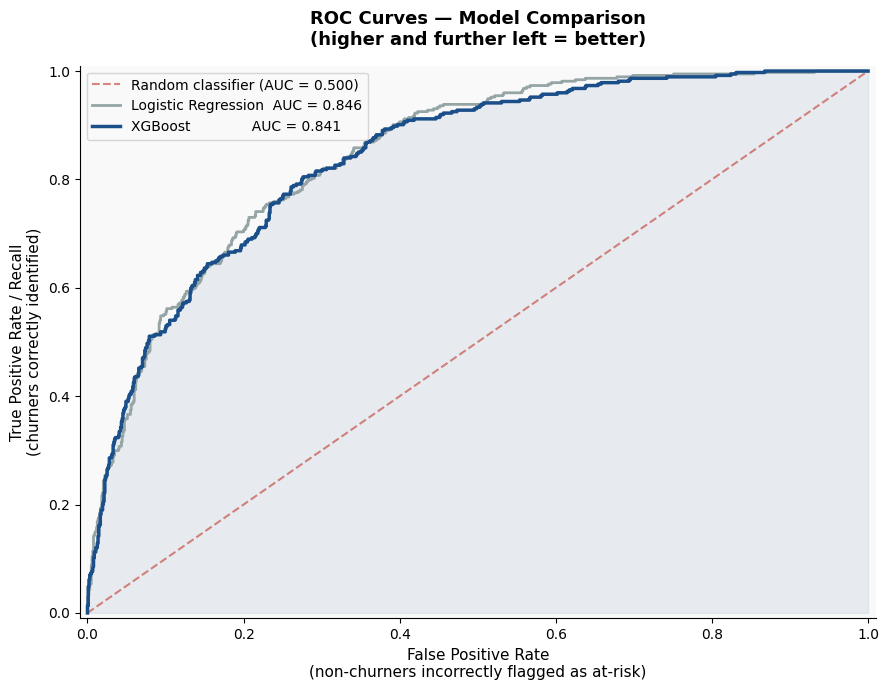

How to interpret AUC-ROC:
AUC = probability that the model ranks a randomly chosen churner
higher than a randomly chosen non-churner.
Our model (0.841) does this correctly 84% of the time.
A perfect model = 1.0. Random guessing = 0.5.


In [8]:
fig, ax = plt.subplots(figsize=(9, 7))

# Random classifier reference
ax.plot([0, 1], [0, 1], color=RED, linestyle='--', lw=1.5,
        label='Random classifier (AUC = 0.500)', alpha=0.6)

# Logistic Regression
fpr_lr, tpr_lr, _ = roc_curve(y_test, lr_probs)
ax.plot(fpr_lr, tpr_lr, color=GREY, lw=2,
        label=f'Logistic Regression  AUC = {lr_auc:.3f}')

# XGBoost
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, xgb_probs)
ax.plot(fpr_xgb, tpr_xgb, color=BLUE, lw=2.5,
        label=f'XGBoost              AUC = {xgb_auc:.3f}')

ax.fill_between(fpr_xgb, tpr_xgb, alpha=0.08, color=BLUE)
ax.set_title('ROC Curves — Model Comparison\n(higher and further left = better)',
             fontweight='bold', pad=15)
ax.set_xlabel('False Positive Rate\n(non-churners incorrectly flagged as at-risk)')
ax.set_ylabel('True Positive Rate / Recall\n(churners correctly identified)')
ax.legend(fontsize=10)
ax.set_xlim(-0.01, 1.01)
ax.set_ylim(-0.01, 1.01)

plt.tight_layout()
plt.savefig(FIGURES / '18_roc_curves.png', dpi=150, bbox_inches='tight')
plt.show()

print("How to interpret AUC-ROC:")
print("AUC = probability that the model ranks a randomly chosen churner")
print("higher than a randomly chosen non-churner.")
print(f"Our model ({xgb_auc:.3f}) does this correctly {xgb_auc*100:.0f}% of the time.")
print("A perfect model = 1.0. Random guessing = 0.5.")


Precision-Recall and threshold selection

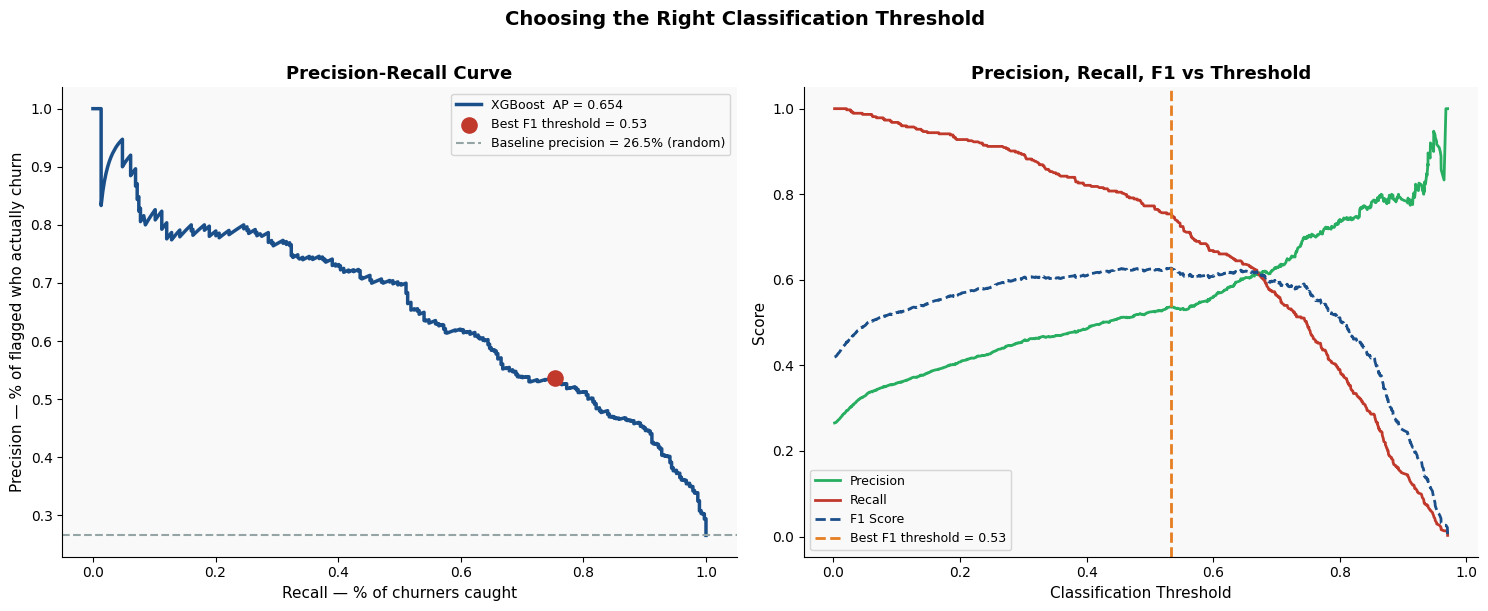

Best F1 threshold   : 0.534
At this threshold:
              precision    recall  f1-score   support

    No Churn       0.90      0.77      0.83      1035
       Churn       0.54      0.75      0.63       374

    accuracy                           0.76      1409
   macro avg       0.72      0.76      0.73      1409
weighted avg       0.80      0.76      0.77      1409


Business interpretation of the threshold decision:
A LOWER threshold catches more churners (higher recall) but
wastes more retention spend on non-churners (lower precision).
A HIGHER threshold is more precise but misses more real churners.
The right threshold depends on the cost of the retention offer vs the LTV of a subscriber.


In [9]:
precision, recall, thresholds = precision_recall_curve(y_test, xgb_probs)
ap_score = average_precision_score(y_test, xgb_probs)

# Find the threshold that maximises F1 score
f1_scores = 2 * (precision * recall) / (precision + recall + 1e-8)
best_idx   = np.argmax(f1_scores[:-1])
best_thresh = thresholds[best_idx]
best_f1     = f1_scores[best_idx]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
fig.suptitle('Choosing the Right Classification Threshold', fontsize=14, fontweight='bold', y=1.01)

# Left: Precision-Recall curve
axes[0].plot(recall, precision, color=BLUE, lw=2.5, label=f'XGBoost  AP = {ap_score:.3f}')
axes[0].scatter(recall[best_idx], precision[best_idx], color=RED, s=120, zorder=5,
                label=f'Best F1 threshold = {best_thresh:.2f}')
axes[0].axhline(y_test.mean(), color=GREY, linestyle='--', lw=1.5,
                label=f'Baseline precision = {y_test.mean()*100:.1f}% (random)')
axes[0].set_title('Precision-Recall Curve', fontweight='bold')
axes[0].set_xlabel('Recall — % of churners caught')
axes[0].set_ylabel('Precision — % of flagged who actually churn')
axes[0].legend(fontsize=9)

# Right: Precision and Recall vs threshold
axes[1].plot(thresholds, precision[:-1], color=GREEN, lw=2, label='Precision')
axes[1].plot(thresholds, recall[:-1],    color=RED,   lw=2, label='Recall')
axes[1].plot(thresholds, f1_scores[:-1], color=BLUE,  lw=2, label='F1 Score', linestyle='--')
axes[1].axvline(best_thresh, color=ORANGE, linestyle='--', lw=2,
                label=f'Best F1 threshold = {best_thresh:.2f}')
axes[1].set_title('Precision, Recall, F1 vs Threshold', fontweight='bold')
axes[1].set_xlabel('Classification Threshold')
axes[1].set_ylabel('Score')
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.savefig(FIGURES / '19_precision_recall.png', dpi=150, bbox_inches='tight')
plt.show()

y_pred = (xgb_probs >= best_thresh).astype(int)
print(f"Best F1 threshold   : {best_thresh:.3f}")
print(f"At this threshold:")
print(classification_report(y_test, y_pred, target_names=['No Churn', 'Churn']))
print()
print("Business interpretation of the threshold decision:")
print("A LOWER threshold catches more churners (higher recall) but")
print("wastes more retention spend on non-churners (lower precision).")
print("A HIGHER threshold is more precise but misses more real churners.")
print("The right threshold depends on the cost of the retention offer vs the LTV of a subscriber.")


Confusion matrix

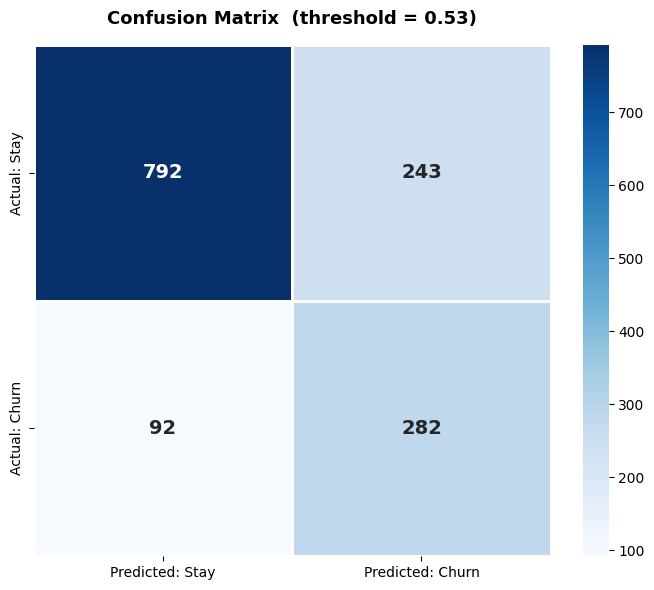

True Positives  (caught churners)           : 282  — correctly flagged for retention
False Positives (non-churners flagged)       : 243  — wasted retention spend
True Negatives  (correctly left alone)       : 792
False Negatives (missed churners)            : 92  — lost revenue we did not try to save

Of the 374 actual churners in the test set, we caught 282 (75%).
Of the 525 subscribers we flagged, 54% actually churned.


In [10]:
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=['Predicted: Stay', 'Predicted: Churn'],
    yticklabels=['Actual: Stay', 'Actual: Churn'],
    linewidths=2, linecolor='white', ax=ax,
    annot_kws={'size': 14, 'weight': 'bold'}
)
ax.set_title(f'Confusion Matrix  (threshold = {best_thresh:.2f})', fontweight='bold', pad=15)

plt.tight_layout()
plt.savefig(FIGURES / '20_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"True Positives  (caught churners)           : {tp:,}  — correctly flagged for retention")
print(f"False Positives (non-churners flagged)       : {fp:,}  — wasted retention spend")
print(f"True Negatives  (correctly left alone)       : {tn:,}")
print(f"False Negatives (missed churners)            : {fn:,}  — lost revenue we did not try to save")
print()
print(f"Of the {tp+fn} actual churners in the test set, we caught {tp} ({tp/(tp+fn)*100:.0f}%).")
print(f"Of the {tp+fp} subscribers we flagged, {tp/(tp+fp)*100:.0f}% actually churned.")


SHAP global feature importance

Calculating SHAP values (may take 30–60 seconds)...


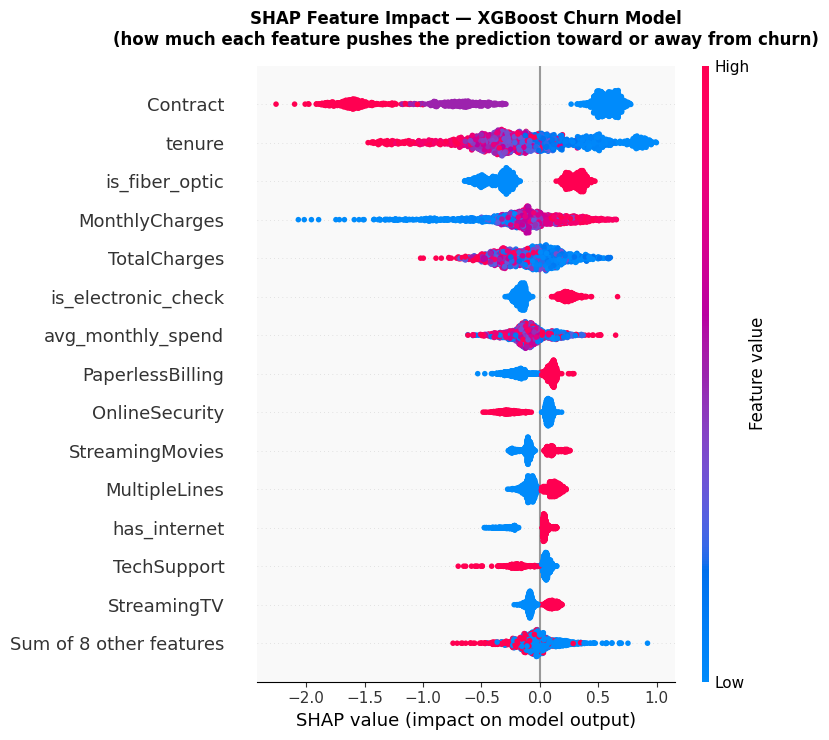


How to read this chart:
- Each row is one feature. Features are ranked top-to-bottom by importance.
- Each dot is one subscriber in the test set.
- Dot position on the X axis = how much that feature increased or decreased their churn risk.
- Dot colour = that subscriber's value for this feature (red=high, blue=low).
- A red dot on the right means: high feature value → increased churn prediction.
- A blue dot on the right means: low feature value → increased churn prediction.


In [11]:
print("Calculating SHAP values (may take 30–60 seconds)...")
explainer    = shap.TreeExplainer(xgb_model)
shap_values  = explainer(X_test)

# Beeswarm plot — one dot per subscriber per feature
# Colour = feature value (red=high, blue=low)
# X position = how much that feature pushed the prediction toward churn
plt.figure(figsize=(11, 8))
shap.plots.beeswarm(shap_values, max_display=15, show=False)
plt.title('SHAP Feature Impact — XGBoost Churn Model\n(how much each feature pushes the prediction toward or away from churn)',
          fontsize=12, fontweight='bold', pad=15)
plt.tight_layout()
plt.savefig(FIGURES / '21_shap_beeswarm.png', dpi=150, bbox_inches='tight')
plt.show()

print()
print("How to read this chart:")
print("- Each row is one feature. Features are ranked top-to-bottom by importance.")
print("- Each dot is one subscriber in the test set.")
print("- Dot position on the X axis = how much that feature increased or decreased their churn risk.")
print("- Dot colour = that subscriber's value for this feature (red=high, blue=low).")
print("- A red dot on the right means: high feature value → increased churn prediction.")
print("- A blue dot on the right means: low feature value → increased churn prediction.")


SHAP individual explanation: waterfall plot

Explaining subscriber at test index 618
Predicted churn probability : 97.0%
Actual outcome              : Churned

Their feature values:
gender                  1.000
SeniorCitizen           1.000
Partner                 0.000
Dependents              0.000
tenure                  1.000
PhoneService            1.000
MultipleLines           1.000
OnlineSecurity          0.000
OnlineBackup            0.000
DeviceProtection        0.000
TechSupport             0.000
StreamingTV             0.000
StreamingMovies         0.000
Contract                0.000
PaperlessBilling        1.000
MonthlyCharges         76.450
TotalCharges           76.450
is_fiber_optic          1.000
has_internet            1.000
is_electronic_check     1.000
avg_monthly_spend      38.225
service_count           0.000



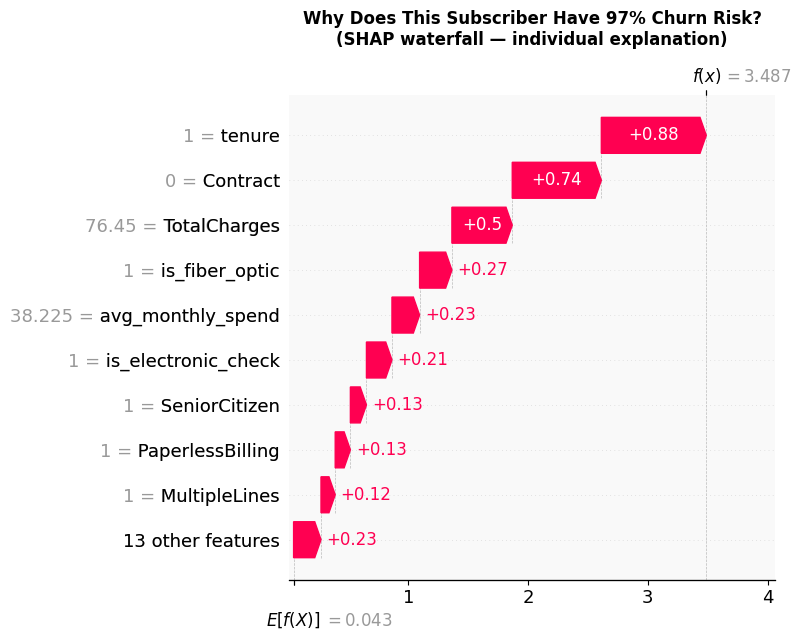


How to read this chart:
- E[f(x)] at the bottom is the model's average prediction across all subscribers.
- f(x) at the top is the prediction for THIS specific subscriber.
- Each bar shows how much one feature pushed the prediction up (red) or down (blue).
- This is what you show a stakeholder who asks 'why is this subscriber high risk?'


In [12]:
# Find a high-risk subscriber in the test set to explain
high_risk_idx = np.argmax(xgb_probs)
prob          = xgb_probs[high_risk_idx]
actual        = y_test.iloc[high_risk_idx]

print(f"Explaining subscriber at test index {high_risk_idx}")
print(f"Predicted churn probability : {prob*100:.1f}%")
print(f"Actual outcome              : {'Churned' if actual == 1 else 'Did not churn'}")
print()
print("Their feature values:")
print(X_test.iloc[high_risk_idx].to_string())
print()

plt.figure(figsize=(11, 7))
shap.plots.waterfall(shap_values[high_risk_idx], show=False)
plt.title(f'Why Does This Subscriber Have {prob*100:.0f}% Churn Risk?\n(SHAP waterfall — individual explanation)',
          fontsize=12, fontweight='bold', pad=15)
plt.tight_layout()
plt.savefig(FIGURES / '22_shap_waterfall_highrisk.png', dpi=150, bbox_inches='tight')
plt.show()

print()
print("How to read this chart:")
print("- E[f(x)] at the bottom is the model's average prediction across all subscribers.")
print("- f(x) at the top is the prediction for THIS specific subscriber.")
print("- Each bar shows how much one feature pushed the prediction up (red) or down (blue).")
print("- This is what you show a stakeholder who asks 'why is this subscriber high risk?'")


Score all active subscribers

In [13]:
# Apply the same feature engineering to ALL active subscribers
active_df = df[df['Churn_Binary'] == 0].copy()

# Rebuild features for the active subscriber base
drop_c = ['customerID', 'Churn', 'Churn_Binary']
for c in ['TenureBand', 'ChargeBand']:
    if c in active_df.columns:
        drop_c.append(c)

X_active = active_df.drop(columns=drop_c).copy()

for col in service_cols:
    X_active[col] = X_active[col].apply(lambda x: 1 if x == 'Yes' else 0)
for col in simple_binary:
    X_active[col] = (X_active[col] == 'Yes').astype(int)

X_active['gender']             = (X_active['gender'] == 'Male').astype(int)
X_active['Contract']           = X_active['Contract'].map({'Month-to-month': 0, 'One year': 1, 'Two year': 2})
X_active['is_fiber_optic']     = (X_active['InternetService'] == 'Fiber optic').astype(int)
X_active['has_internet']       = (X_active['InternetService'] != 'No').astype(int)
X_active                       = X_active.drop(columns=['InternetService'])
X_active['is_electronic_check'] = (X_active['PaymentMethod'] == 'Electronic check').astype(int)
X_active                        = X_active.drop(columns=['PaymentMethod'])
X_active['avg_monthly_spend']  = X_active['TotalCharges'] / (X_active['tenure'] + 1)
X_active['service_count']      = X_active[['OnlineSecurity','OnlineBackup','DeviceProtection',
                                             'TechSupport','StreamingTV','StreamingMovies']].sum(axis=1)

# Score
active_df['churn_probability'] = xgb_model.predict_proba(X_active)[:, 1]
active_df['risk_tier'] = pd.cut(
    active_df['churn_probability'],
    bins=[0, 0.30, 0.60, 1.0],
    labels=['Low Risk', 'Medium Risk', 'High Risk']
)

print("Active subscriber base — churn risk distribution:")
print()
print(active_df['risk_tier'].value_counts().to_string())
print()
print(f"Total active subscribers scored: {len(active_df):,}")
print()
print("Top 10 highest-risk active subscribers:")
print(
    active_df[['customerID', 'tenure', 'Contract', 'MonthlyCharges',
               'churn_probability', 'risk_tier']]
    .sort_values('churn_probability', ascending=False)
    .head(10)
    .to_string(index=False)
)


Active subscriber base — churn risk distribution:

risk_tier
Low Risk       3269
Medium Risk    1123
High Risk       782

Total active subscribers scored: 5,174

Top 10 highest-risk active subscribers:
customerID  tenure       Contract  MonthlyCharges  churn_probability risk_tier
2254-DLXRI       1 Month-to-month           79.15           0.964657 High Risk
4912-PIGUY       1 Month-to-month           84.60           0.957310 High Risk
2754-SDJRD       8 Month-to-month          100.15           0.948206 High Risk
1452-VOQCH       1 Month-to-month           75.10           0.948189 High Risk
5150-ITWWB       3 Month-to-month           94.85           0.946959 High Risk
4445-ZJNMU       9 Month-to-month           99.30           0.942714 High Risk
0021-IKXGC       1 Month-to-month           72.10           0.941921 High Risk
7439-DKZTW       1 Month-to-month           80.55           0.940009 High Risk
8161-QYMTT       7 Month-to-month           94.10           0.939223 High Risk
9603-OAI

Revenue impact calculator

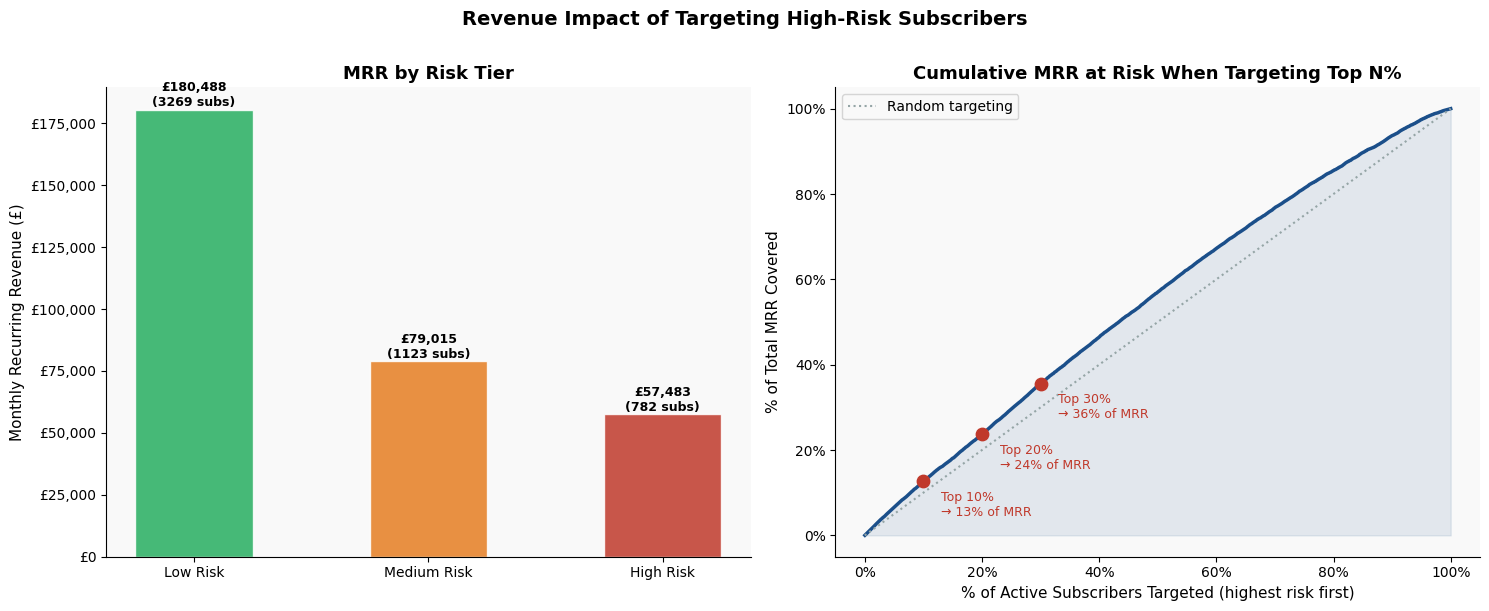


Revenue impact by risk tier:
             Total MRR  Subscribers  Avg Monthly
risk_tier                                       
Low Risk     180488.35         3269    55.212099
Medium Risk   79014.85         1123    70.360508
High Risk     57482.55          782    73.507097

MRR at risk in High Risk tier   : £57,483  (18% of total active MRR)

By targeting just the High Risk tier, a retention campaign addresses the
highest-concentration MRR at risk with the smallest outreach volume.


In [14]:
active_sorted = active_df.sort_values('churn_probability', ascending=False).reset_index(drop=True)
active_sorted['rank']       = active_sorted.index + 1
active_sorted['rank_pct']   = active_sorted['rank'] / len(active_sorted) * 100
active_sorted['cum_mrr']    = active_sorted['MonthlyCharges'].cumsum()
active_sorted['cum_mrr_pct']= active_sorted['cum_mrr'] / active_sorted['MonthlyCharges'].sum() * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
fig.suptitle('Revenue Impact of Targeting High-Risk Subscribers', fontsize=14, fontweight='bold', y=1.01)

# Left: MRR at risk by risk tier
tier_mrr = active_df.groupby('risk_tier', observed=True)['MonthlyCharges'].agg(['sum', 'count', 'mean'])
tier_mrr.columns = ['Total MRR', 'Subscribers', 'Avg Monthly']
colors_tier = [GREEN, ORANGE, RED]
bars = axes[0].bar(tier_mrr.index, tier_mrr['Total MRR'],
                   color=colors_tier, alpha=0.85, edgecolor='white', width=0.5)
axes[0].set_title('MRR by Risk Tier', fontweight='bold')
axes[0].set_ylabel('Monthly Recurring Revenue (£)')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'£{v:,.0f}'))
for bar, (_, row) in zip(bars, tier_mrr.iterrows()):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 100,
                 f"£{row['Total MRR']:,.0f}\n({int(row['Subscribers'])} subs)",
                 ha='center', va='bottom', fontsize=9, fontweight='bold')

# Right: Cumulative MRR captured by targeting top N% of subscribers
axes[1].plot(active_sorted['rank_pct'], active_sorted['cum_mrr_pct'],
             color=BLUE, lw=2.5)
axes[1].fill_between(active_sorted['rank_pct'], active_sorted['cum_mrr_pct'],
                     alpha=0.1, color=BLUE)
for pct in [10, 20, 30]:
    row = active_sorted[active_sorted['rank_pct'] >= pct].iloc[0]
    axes[1].scatter([pct], [row['cum_mrr_pct']], color=RED, s=80, zorder=5)
    axes[1].annotate(f'Top {pct}%\n→ {row["cum_mrr_pct"]:.0f}% of MRR',
                     xy=(pct, row['cum_mrr_pct']),
                     xytext=(pct + 3, row['cum_mrr_pct'] - 8),
                     fontsize=9, color=RED)
axes[1].plot([0, 100], [0, 100], color=GREY, linestyle=':', lw=1.5, label='Random targeting')
axes[1].set_title('Cumulative MRR at Risk When Targeting Top N%', fontweight='bold')
axes[1].set_xlabel('% of Active Subscribers Targeted (highest risk first)')
axes[1].set_ylabel('% of Total MRR Covered')
axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{v:.0f}%'))
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{v:.0f}%'))
axes[1].legend()

plt.tight_layout()
plt.savefig(FIGURES / '23_revenue_impact.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nRevenue impact by risk tier:")
print(tier_mrr.to_string())
print()
total_active_mrr = active_df['MonthlyCharges'].sum()
high_risk_mrr    = tier_mrr.loc['High Risk', 'Total MRR']
print(f"MRR at risk in High Risk tier   : £{high_risk_mrr:,.0f}  ({high_risk_mrr/total_active_mrr*100:.0f}% of total active MRR)")
print()
print("By targeting just the High Risk tier, a retention campaign addresses the")
print(f"highest-concentration MRR at risk with the smallest outreach volume.")


Save model and scored subscriber list

In [15]:
# Save trained model
model_path = MODELS / 'xgb_churn_model.pkl'
with open(model_path, 'wb') as f:
    pickle.dump(xgb_model, f)
print(f"Model saved: {model_path}")

# Save scaler
scaler_path = MODELS / 'standard_scaler.pkl'
with open(scaler_path, 'wb') as f:
    pickle.dump(scaler, f)
print(f"Scaler saved: {scaler_path}")

# Ensure the processed directory exists before saving
PROCESSED.mkdir(parents=True, exist_ok=True)

# Save scored subscriber list
scored_path = PROCESSED / 'subscribers_scored.csv'
active_df[['customerID', 'tenure', 'Contract', 'MonthlyCharges', 'TotalCharges',
           'churn_probability', 'risk_tier']].sort_values(
    'churn_probability', ascending=False
).to_csv(scored_path, index=False)
print(f"Scored subscribers saved: {scored_path}  ({len(active_df):,} rows)")

print()
print("Download these files from /content/models/ and /content/processed/")
print("before your Colab session ends.")


Model saved: /content/models/xgb_churn_model.pkl
Scaler saved: /content/models/standard_scaler.pkl
Scored subscribers saved: /content/processed/subscribers_scored.csv  (5,174 rows)

Download these files from /content/models/ and /content/processed/
before your Colab session ends.


In [16]:
print("=" * 65)
print("NOTEBOOK 04 COMPLETE — MODEL SUMMARY")
print("=" * 65)
print()
print(f"Logistic Regression AUC : {lr_auc:.4f}  (baseline)")
print(f"XGBoost AUC             : {xgb_auc:.4f}  (main model)")
print(f"Improvement             : +{(xgb_auc-lr_auc)*100:.1f} AUC points")
print(f"Best F1 threshold       : {best_thresh:.3f}")
print(f"At that threshold:")
print(f"  Precision : {tp/(tp+fp)*100:.0f}%  (of flagged subscribers, this % actually churn)")
print(f"  Recall    : {tp/(tp+fn)*100:.0f}%  (of all churners, this % were caught)")
print()

NOTEBOOK 04 COMPLETE — MODEL SUMMARY

Logistic Regression AUC : 0.8461  (baseline)
XGBoost AUC             : 0.8405  (main model)
Improvement             : +-0.6 AUC points
Best F1 threshold       : 0.534
At that threshold:
  Precision : 54%  (of flagged subscribers, this % actually churn)
  Recall    : 75%  (of all churners, this % were caught)

